In [1]:
from pathlib import Path
import sys
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import torch

ROOT = Path.cwd()

for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, build_kaist_sequence_specs

from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SE3NoiseConfig, VectorNoiseConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.calibration.context import calibration_state_to_context
from obscalib.calibration.observability_targets import ObservabilityTargetCache
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import MeasurementType
from obscalib.geometry.lie import se3_exp, se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.obs_calib_model import ObsCalibModel
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, read_training_checkpoint

In [2]:
##################################################
# Checkpoint
##################################################

RUN_NAME = "kaist_calibration_cached_observability_standard_smooth_l1_001"
CHECKPOINT_PATH = ROOT / "runs" / RUN_NAME / "best.pt"

##################################################
# Compute device
##################################################

DEVICE_NAME = "cuda"
DEVICE = torch.device(DEVICE_NAME)
MODEL_DTYPE = torch.float32

##################################################
# Dataset location
##################################################

KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

##################################################
# Rollout sequence
##################################################

SEQUENCE_NAME = "Urban38"
ROLLOUT_START_WINDOW = 0
ROLLOUT_NUM_WINDOWS = None
RUN_PREFLIGHT = True

##################################################
# Initial calibration error
##################################################
#
# delta_xi follows [phi_x, phi_y, phi_z, rho_x, rho_y, rho_z] and is applied with the same left perturbation used during training:
#
# T_initial = Exp(delta_xi) @ T_true
##################################################

INITIAL_DELTA_XI = {"imu": np.array([np.deg2rad(8.0), np.deg2rad(-6.0), np.deg2rad(5.0), 0.08, -0.05, 0.04]), 
                    "lidar": np.array([np.deg2rad(-8.0), np.deg2rad(6.0), np.deg2rad(-5.0), -0.08, 0.05, -0.04])}
INITIAL_DELTA_TAU_S = {"imu": 0.020, "lidar": -0.020}

##################################################
# Cached observability
##################################################

OBSERVABILITY_CACHE_DIR = ROOT / "outputs" / "observability_targets"

##################################################
# Rollout augmentations
##################################################
#
# Measurement noise is safe to sample independently in every rollout window:
# it changes measurements but not the desired clean observability target.
#
# Do not independently apply prior perturbation in every rollout window:
# the carried calibration already IS the prior for the next step.
#
# Do not independently apply frame randomization in every rollout window:
# it changes the coordinate representation of the carried calibration state.
##################################################

USE_MEASUREMENT_NOISE = True
ROLLOUT_AUGMENTATION_SEED = 56789

In [3]:
checkpoint_data = read_training_checkpoint(
    CHECKPOINT_PATH,
    map_location="cpu",
)

experiment = checkpoint_data.get(
    "extra_state",
    {},
).get(
    "experiment"
)

if experiment is None:
    raise ValueError(
        "This checkpoint does not contain an experiment snapshot."
    )

if "observability_config" not in experiment:
    raise ValueError(
        "This checkpoint does not contain observability_config."
    )

model_config = experiment["model_config"]
windowing_config = experiment["windowing_config"]
rig_calibration = experiment["rig_calibration"]
measurement_dim = experiment["measurement_dim"]
observability_config = experiment["observability_config"]

##################################################
# Cached-observability contract
##################################################

OBSERVABILITY_SOURCE = observability_config["source"]

CALIBRATION_KEYS = tuple(
    observability_config.get(
        "calibration_keys",
        model_config.head_keys,
    )
)

OBSERVABILITY_COORDINATE_ORDER = tuple(
    observability_config.get(
        "coordinate_order",
        (
            "phi_x",
            "phi_y",
            "phi_z",
            "rho_x",
            "rho_y",
            "rho_z",
            "tau",
        ),
    )
)

OBSERVABILITY_TOKEN_FEATURE_DIM = int(
    observability_config["token_feature_dim"]
)

OBSERVABILITY_FEATURE_DIM = int(
    observability_config["feature_dim"]
)

BASE_TOKEN_INPUT_DIM = measurement_dim + 2

EXPECTED_TOKEN_INPUT_DIM = (
    BASE_TOKEN_INPUT_DIM
    + OBSERVABILITY_TOKEN_FEATURE_DIM
)

if tuple(model_config.head_keys) != CALIBRATION_KEYS:
    raise ValueError(
        f"Checkpoint model heads {tuple(model_config.head_keys)} do not match "
        f"cached observability keys {CALIBRATION_KEYS}."
    )

if model_config.transformer.input_dim != EXPECTED_TOKEN_INPUT_DIM:
    raise ValueError(
        f"Checkpoint token input dimension mismatch: model expects "
        f"{model_config.transformer.input_dim}, while measurement_dim={measurement_dim} "
        f"and local cached observability dimension={OBSERVABILITY_TOKEN_FEATURE_DIM} "
        f"imply {EXPECTED_TOKEN_INPUT_DIM}."
    )

print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint epoch:", checkpoint_data.get("epoch"))
print("Sequence split:", experiment["sequence_split"])
print("Observability source:", OBSERVABILITY_SOURCE)
print("Calibration keys:", CALIBRATION_KEYS)
print("Observability coordinate order:", OBSERVABILITY_COORDINATE_ORDER)
print("Global cached observability dimension:", OBSERVABILITY_FEATURE_DIM)
print("Per-calibration token observability dimension:", OBSERVABILITY_TOKEN_FEATURE_DIM)
print("Transformer token input dimension:", model_config.transformer.input_dim)

print()
print("Model configuration:")
print(model_config)

print()
print("Window configuration:")
print(windowing_config)

Checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_calibration_cached_observability_standard_smooth_l1_001/best.pt
Checkpoint epoch: 100
Sequence split: {'train': ('Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16'), 'validation': ('Urban26', 'Urban28'), 'test': ('Urban38', 'Urban39')}
Observability source: cached_dimensionless_soft_projector
Calibration keys: ('imu', 'lidar')
Observability coordinate order: ('phi_x', 'phi_y', 'phi_z', 'rho_x', 'rho_y', 'rho_z', 'tau')
Global cached observability dimension: 14
Per-calibration token observability dimension: 7
Transformer token input dimension: 15

Model configuration:
ObsCalibModelConfig(transformer=TransformerConfig(input_dim=15, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.1, num_summary_tokens=4, activation='gelu'), mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.1), calibration_head=CalibrationHeadConfig(calibration_context_dim=7, hid

In [4]:
sequence_split = experiment["sequence_split"]

##################################################
# Determine which cached split contains this sequence
##################################################

if SEQUENCE_NAME in sequence_split["train"]:
    OBSERVABILITY_CACHE_SPLIT = "train"
    CACHE_SEQUENCE_NAMES = tuple(sequence_split["train"])

elif SEQUENCE_NAME in sequence_split["validation"]:
    OBSERVABILITY_CACHE_SPLIT = "validation"
    CACHE_SEQUENCE_NAMES = tuple(sequence_split["validation"])

elif SEQUENCE_NAME in sequence_split["test"]:
    OBSERVABILITY_CACHE_SPLIT = "test"
    CACHE_SEQUENCE_NAMES = tuple(sequence_split["test"])

else:
    raise ValueError(
        f"Sequence {SEQUENCE_NAME!r} does not belong to the checkpoint's "
        "recorded train/validation/test split."
    )

##################################################
# Single-sequence dataset used by the sequential rollout
##################################################

sequence_spec = build_kaist_sequence_specs(
    sequence_names=[SEQUENCE_NAME],
    kaist_dataset_root=KAIST_DATASET_ROOT,
    lidar_pose_root=LIDAR_POSE_ROOT,
)[0]

rollout_dataset = KAISTCalibrationDataset(
    [sequence_spec],
    rig_calibration,
    windowing_config,
    measurement_dtype=torch.float32,
    source_timestamp_dtype=torch.float64,
    window_timestamp_dtype=torch.float32,
)

##################################################
# Full split dataset used only to map local rollout
# indices to rows in the cached observability tensor
##################################################

cache_sequence_specs = build_kaist_sequence_specs(
    sequence_names=CACHE_SEQUENCE_NAMES,
    kaist_dataset_root=KAIST_DATASET_ROOT,
    lidar_pose_root=LIDAR_POSE_ROOT,
)

cache_dataset = KAISTCalibrationDataset(
    cache_sequence_specs,
    rig_calibration,
    windowing_config,
    measurement_dtype=torch.float32,
    source_timestamp_dtype=torch.float64,
    window_timestamp_dtype=torch.float32,
)

cache_sequence_indices = [
    dataset_index
    for dataset_index in range(
        len(cache_dataset)
    )
    if cache_dataset.sequence_name_for_window(
        dataset_index
    )
    == SEQUENCE_NAME
]

if len(cache_sequence_indices) != len(rollout_dataset):
    raise RuntimeError(
        f"Cache/index alignment failed for {SEQUENCE_NAME!r}: "
        f"rollout dataset has {len(rollout_dataset)} windows, "
        f"but split dataset contains {len(cache_sequence_indices)} matching windows."
    )

print(rollout_dataset.summary())

print()
print("Observability cache split:", OBSERVABILITY_CACHE_SPLIT)
print(
    "Cache rows:",
    cache_sequence_indices[0],
    "...",
    cache_sequence_indices[-1],
)

KAISTCalibrationDataset: 349 windows from 1 sequences
approximate tensor storage: 6.5 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiDAR=17005

Observability cache split: test
Cache rows: 0 ... 348


In [5]:
##################################################
# Load cached dimensionless soft-projector observability
##################################################

OBSERVABILITY_CACHE_PATH = (
    OBSERVABILITY_CACHE_DIR
    / f"{OBSERVABILITY_CACHE_SPLIT}.pt"
)

if not OBSERVABILITY_CACHE_PATH.exists():
    raise FileNotFoundError(
        f"Cached observability file does not exist: "
        f"{OBSERVABILITY_CACHE_PATH}"
    )

saved_observability_cache = torch.load(
    OBSERVABILITY_CACHE_PATH,
    map_location="cpu",
    weights_only=True,
)

if not isinstance(
    saved_observability_cache,
    dict,
):
    raise TypeError(
        "Cached observability file must contain a dictionary."
    )

cache_calibration_keys = tuple(
    saved_observability_cache[
        "calibration_keys"
    ]
)

if cache_calibration_keys != CALIBRATION_KEYS:
    raise ValueError(
        f"Cache calibration keys {cache_calibration_keys} "
        f"do not match checkpoint keys {CALIBRATION_KEYS}."
    )

cached_observability_values = (
    saved_observability_cache[
        "values"
    ]
    .detach()
    .to(
        device="cpu",
        dtype=torch.float32,
    )
)

expected_cache_shape = (
    len(cache_dataset),
    len(CALIBRATION_KEYS),
    OBSERVABILITY_TOKEN_FEATURE_DIM,
)

if tuple(
    cached_observability_values.shape
) != expected_cache_shape:
    raise ValueError(
        f"Cached observability has shape "
        f"{tuple(cached_observability_values.shape)}, "
        f"expected {expected_cache_shape}."
    )

if not torch.isfinite(
    cached_observability_values
).all():
    raise ValueError(
        "Cached observability contains non-finite values."
    )

rollout_observability_cache = ObservabilityTargetCache(
    values=cached_observability_values,
    calibration_keys=CALIBRATION_KEYS,
)


def cached_observability_for_rollout_index(
    rollout_dataset_index,
    *,
    device,
    dtype,
):
    """
    Return cached observability for one local sequence window.

    calibration_features:
        calibration key -> [1, 7]

    features:
        [1, 14], retained for diagnostics/bookkeeping.
    """

    cache_dataset_index = cache_sequence_indices[
        rollout_dataset_index
    ]

    cache_index_tensor = torch.tensor(
        [cache_dataset_index],
        dtype=torch.long,
        device="cpu",
    )

    calibration_features = (
        rollout_observability_cache.targets_for_indices(
            cache_index_tensor,
            device=device,
            dtype=dtype,
        )
    )

    global_features = torch.cat(
        [
            calibration_features[
                calibration_key
            ]
            for calibration_key in CALIBRATION_KEYS
        ],
        dim=-1,
    )

    return SimpleNamespace(
        raw=None,
        features=global_features,
        calibration_features=calibration_features,
        cache_dataset_index=cache_dataset_index,
    )


print(
    "Loaded cached observability:",
    OBSERVABILITY_CACHE_PATH,
)

print(
    "Full cache shape:",
    tuple(
        cached_observability_values.shape
    ),
)

Loaded cached observability: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/outputs/observability_targets/test.pt
Full cache shape: (699, 2, 7)


In [6]:
##################################################
# Rollout augmentation
##################################################
#
# Sampling-rate augmentation is deliberately OFF:
# it changes the observability target.
#
# Calibration events are OFF:
# they change the calibration target semantics.
#
# Prior perturbation is OFF here because the sequentially
# carried calibration is already the current prior.
#
# Frame randomization is OFF here because independently
# changing sensor coordinates every rollout window would
# also require transforming the carried calibration state.
##################################################

rollout_augmentation_config = AugmentationConfig(
    sampling_rate=SamplingRateAugmentationConfig(
        enabled=False,
    ),

    frame_randomization=FrameRandomizationConfig(
        enabled=False,
    ),

    prior_perturbation=PriorPerturbationConfig(
        enabled=False,
    ),

    calibration_event=CalibrationEventConfig(
        enabled=False,
    ),

    noise=NoiseAugmentationConfig(
        enabled=USE_MEASUREMENT_NOISE,

        vector_by_type={
            MeasurementType.IMU_GYROSCOPE: VectorNoiseConfig(
                gaussian_std=0.01,
                window_bias_std=0.003,
            ),

            MeasurementType.IMU_ACCELEROMETER: VectorNoiseConfig(
                gaussian_std=0.08,
                window_bias_std=0.03,
            ),
        },

        se3_by_type={
            MeasurementType.LIDAR_POSE: SE3NoiseConfig(
                rotation_std=np.deg2rad(0.15),
                translation_std=0.01,
            ),
        },
    ),
)

rollout_augmentation_pipeline = AugmentationPipeline(
    rollout_augmentation_config
)

rollout_augmentation_generator = torch.Generator(
    device=DEVICE.type
).manual_seed(
    ROLLOUT_AUGMENTATION_SEED
)

print(
    "Measurement-noise augmentation:",
    USE_MEASUREMENT_NOISE,
)

Measurement-noise augmentation: True


In [7]:
##################################################
# Model and cached-observability rollout step
##################################################

model = ObsCalibModel(
    model_config
).to(
    device=DEVICE,
    dtype=MODEL_DTYPE,
)

load_training_checkpoint(
    CHECKPOINT_PATH,
    model=model,
    map_location=DEVICE,
    restore_rng_state=False,
)

model.eval()

geometry_processor = GeometryProcessor()

tokenizer = Tokenizer(
    measurement_dim=measurement_dim,
    calibration_keys=CALIBRATION_KEYS,
)

calibration_updater = CalibrationUpdater()


def forward_cached_rollout_step(
    window,
    calibration,
    observability,
):
    """
    Run one sequential calibration step using cached observability.

    The carried calibration is used for geometry normalization and
    calibration-head context.

    Each measurement token receives only the 7D observability vector
    associated with its own physical calibration.
    """

    ##################################################
    # Geometry using carried calibration
    ##################################################

    canonical_streams = geometry_processor(
        window.streams,
        window.metadata,
        calibration,
    )

    ##################################################
    # Base measurement tokens
    ##################################################

    tokens = tokenizer(
        canonical_streams,
        observability=None,
    )

    if tokens.calibration_ids is None:
        raise RuntimeError(
            "Tokenizer must emit calibration_ids."
        )

    if tokens.x.shape[-1] != BASE_TOKEN_INPUT_DIM:
        raise RuntimeError(
            f"Base tokenizer produced dimension "
            f"{tokens.x.shape[-1]}, expected "
            f"{BASE_TOKEN_INPUT_DIM}."
        )

    ##################################################
    # Calibration-local cached observability
    ##################################################

    token_observability = torch.zeros(
        (
            tokens.x.shape[0],
            tokens.x.shape[1],
            OBSERVABILITY_TOKEN_FEATURE_DIM,
        ),
        dtype=tokens.x.dtype,
        device=tokens.x.device,
    )

    for calibration_id, calibration_key in enumerate(
        CALIBRATION_KEYS
    ):
        calibration_observability = (
            observability.calibration_features[
                calibration_key
            ]
            .to(
                device=tokens.x.device,
                dtype=tokens.x.dtype,
            )
        )

        calibration_mask = (
            tokens.calibration_ids
            == calibration_id
        )

        token_observability = torch.where(
            calibration_mask.unsqueeze(-1),
            calibration_observability[
                :,
                None,
                :,
            ],
            token_observability,
        )

    tokens.x = torch.cat(
        [
            tokens.x,
            token_observability,
        ],
        dim=-1,
    )

    if tokens.x.shape[-1] != EXPECTED_TOKEN_INPUT_DIM:
        raise RuntimeError(
            f"Final token dimension is "
            f"{tokens.x.shape[-1]}, expected "
            f"{EXPECTED_TOKEN_INPUT_DIM}."
        )

    tokens.validate()

    ##################################################
    # Calibration-head context from carried state
    ##################################################

    calibration_context = {
        calibration_key: calibration_state_to_context(
            calibration[
                calibration_key
            ]
        )
        for calibration_key in model_config.head_keys
    }

    ##################################################
    # Predict update
    ##################################################

    model_output = model(
        tokens,
        calibration_context,
    )

    ##################################################
    # Carry predicted state forward
    ##################################################

    next_calibration = dict(
        calibration
    )

    for calibration_key, prediction in (
        model_output.predictions.items()
    ):
        next_calibration[
            calibration_key
        ] = calibration_updater.update(
            calibration[
                calibration_key
            ],
            prediction,
        )

    return SimpleNamespace(
        model_output=model_output,
        next_calibration=next_calibration,
        tokens=tokens,
        observability=observability,
    )


print(
    "Parameters:",
    sum(
        parameter.numel()
        for parameter in model.parameters()
    ),
)

print(
    "Expected token dimension:",
    EXPECTED_TOKEN_INPUT_DIM,
)

Parameters: 2615058
Expected token dimension: 15


In [8]:
num_available_windows = len(rollout_dataset)
rollout_end_window = num_available_windows if ROLLOUT_NUM_WINDOWS is None else min(ROLLOUT_START_WINDOW + ROLLOUT_NUM_WINDOWS, num_available_windows)
rollout_indices = list(range(ROLLOUT_START_WINDOW, rollout_end_window))

if not rollout_indices:
    raise ValueError("The selected rollout contains no windows.")

print("Rollout windows:", len(rollout_indices))
print("Window range:", rollout_indices[0], "...", rollout_indices[-1])
print("Approximate rollout duration [s]:", len(rollout_indices) * windowing_config.window_stride_s)

Rollout windows: 349
Window range: 0 ... 348
Approximate rollout duration [s]: 1745.0


In [9]:
##################################################
# Initial carried calibration
##################################################

first_window = collate_windows([rollout_dataset[rollout_indices[0]]])
first_window = window_batch_to(first_window, DEVICE, dtype=MODEL_DTYPE)

true_calibration = {calibration_key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for calibration_key, state in first_window.current_calibration.items()}
initial_calibration = {}

for calibration_key, true_state in true_calibration.items():
    delta_xi = torch.as_tensor(INITIAL_DELTA_XI[calibration_key], dtype=MODEL_DTYPE, device=DEVICE).reshape(1, 6)
    delta_tau = torch.tensor([[INITIAL_DELTA_TAU_S[calibration_key]]], dtype=MODEL_DTYPE, device=DEVICE)
    initial_calibration[calibration_key] = CalibrationState(transform=se3_exp(delta_xi) @ true_state.transform, time_offset=true_state.time_offset + delta_tau)

for calibration_key, state in initial_calibration.items():
    print(calibration_key, "initial tau [ms] =", 1000.0 * float(state.time_offset[0, 0].detach().cpu()))

imu initial tau [ms] = 19.999999552965164
lidar initial tau [ms] = -19.999999552965164


In [10]:
def calibration_state_error(estimate: CalibrationState, reference: CalibrationState):
    """Return the correction required to move estimate to reference."""
    error_transform = reference.transform @ torch.linalg.inv(estimate.transform)
    error_xi = se3_log(error_transform)
    error_tau = reference.time_offset - estimate.time_offset
    return error_xi, error_tau

In [11]:
##################################################
# Optional first-window cached-observability preflight
##################################################

if RUN_PREFLIGHT:
    preflight_window = collate_windows(
        [
            rollout_dataset[
                rollout_indices[0]
            ]
        ]
    )

    preflight_window = window_batch_to(
        preflight_window,
        DEVICE,
        dtype=MODEL_DTYPE,
    )

    ##################################################
    # Apply the same optional nuisance augmentation
    # used during the actual rollout.
    ##################################################

    preflight_generator = torch.Generator(
        device=DEVICE.type
    ).manual_seed(
        ROLLOUT_AUGMENTATION_SEED
    )

    preflight_augmentation = (
        rollout_augmentation_pipeline(
            preflight_window,
            generator=preflight_generator,
        )
    )

    preflight_window = (
        preflight_augmentation.augmented_window
    )

    ##################################################
    # Cached raw-window observability
    ##################################################

    preflight_observability = (
        cached_observability_for_rollout_index(
            rollout_indices[0],
            device=DEVICE,
            dtype=MODEL_DTYPE,
        )
    )

    with torch.no_grad():
        preflight_result = (
            forward_cached_rollout_step(
                preflight_window,
                initial_calibration,
                preflight_observability,
            )
        )

    print(
        "Preflight global cached observability shape:",
        tuple(
            preflight_observability.features.shape
        ),
    )

    for calibration_key in CALIBRATION_KEYS:
        print()
        print(
            calibration_key,
            "cached observability:",
        )
        print(
            preflight_observability.calibration_features[
                calibration_key
            ][0]
        )

    print()
    print(
        "Preflight token shape:",
        tuple(
            preflight_result.tokens.x.shape
        ),
    )

    print(
        "Preflight token input dimension:",
        preflight_result.tokens.x.shape[-1],
    )

/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Preflight global cached observability shape: (1, 14)

imu cached observability:
tensor([2.1567e-01, 3.0657e-01, 2.4647e-01, 3.5877e-19, 6.9938e-17, 5.6537e-17,
        8.6861e-01], device='cuda:0')

lidar cached observability:
tensor([2.1567e-01, 3.0658e-01, 2.4647e-01, 9.5989e-30, 1.2243e-29, 1.0711e-29,
        6.0934e-01], device='cuda:0')

Preflight token shape: (1, 1049, 15)
Preflight token input dimension: 15


In [12]:
torch.cuda.empty_cache()

In [13]:
##################################################
# Sequential rollout
##################################################

rollout_history = {
    calibration_key: {
        "error_before_xi": [],
        "error_after_xi": [],
        "error_before_tau": [],
        "error_after_tau": [],
        "predicted_delta_xi": [],
        "predicted_delta_tau": [],
        "event_probability": [],
        "change_time": [],
    }
    for calibration_key in model_config.head_keys
}

observability_history = {
    calibration_key: []
    for calibration_key in CALIBRATION_KEYS
}

calibration = {
    calibration_key: CalibrationState(
        transform=state.transform.clone(),
        time_offset=state.time_offset.clone(),
    )
    for calibration_key, state in initial_calibration.items()
}

rollout_augmentation_generator = torch.Generator(
    device=DEVICE.type
).manual_seed(
    ROLLOUT_AUGMENTATION_SEED
)

model.eval()

with torch.no_grad():
    for rollout_step, dataset_index in enumerate(
        rollout_indices
    ):
        ##################################################
        # Load real physical window
        ##################################################

        raw_window = collate_windows(
            [
                rollout_dataset[
                    dataset_index
                ]
            ]
        )

        raw_window = window_batch_to(
            raw_window,
            DEVICE,
            dtype=MODEL_DTYPE,
        )

        ##################################################
        # Fixed physical reference calibration
        ##################################################

        reference_calibration = (
            raw_window.current_calibration
        )

        ##################################################
        # State error before learned update
        ##################################################

        for calibration_key in model_config.head_keys:
            error_xi, error_tau = (
                calibration_state_error(
                    calibration[
                        calibration_key
                    ],
                    reference_calibration[
                        calibration_key
                    ],
                )
            )

            rollout_history[
                calibration_key
            ][
                "error_before_xi"
            ].append(
                error_xi[0].cpu()
            )

            rollout_history[
                calibration_key
            ][
                "error_before_tau"
            ].append(
                error_tau[0].cpu()
            )

        ##################################################
        # Target-preserving measurement augmentation
        ##################################################

        augmentation_result = (
            rollout_augmentation_pipeline(
                raw_window,
                generator=rollout_augmentation_generator,
            )
        )

        model_window = (
            augmentation_result.augmented_window
        )

        ##################################################
        # Cached observability from the original window
        ##################################################

        observability = (
            cached_observability_for_rollout_index(
                dataset_index,
                device=DEVICE,
                dtype=MODEL_DTYPE,
            )
        )

        for calibration_key in CALIBRATION_KEYS:
            observability_history[
                calibration_key
            ].append(
                observability.calibration_features[
                    calibration_key
                ][0].detach().cpu()
            )

        ##################################################
        # Sequential model step
        ##################################################

        try:
            result = (
                forward_cached_rollout_step(
                    model_window,
                    calibration,
                    observability,
                )
            )

        except Exception as exc:
            current_tau_ms = {
                calibration_key:
                    1000.0
                    * float(
                        state.time_offset[
                            0,
                            0,
                        ]
                        .detach()
                        .cpu()
                    )
                for calibration_key, state
                in calibration.items()
            }

            raise RuntimeError(
                f"Sequential rollout failed at "
                f"rollout step {rollout_step}, "
                f"dataset window {dataset_index}, "
                f"current tau [ms] {current_tau_ms}."
            ) from exc

        ##################################################
        # Predicted corrections
        ##################################################

        for calibration_key, prediction in (
            result.model_output.predictions.items()
        ):
            rollout_history[
                calibration_key
            ][
                "predicted_delta_xi"
            ].append(
                prediction.delta_xi[
                    0
                ].cpu()
            )

            rollout_history[
                calibration_key
            ][
                "predicted_delta_tau"
            ].append(
                prediction.delta_tau[
                    0
                ].cpu()
            )

            rollout_history[
                calibration_key
            ][
                "event_probability"
            ].append(
                torch.sigmoid(
                    prediction.change_event_logit[
                        0
                    ]
                ).cpu()
            )

            rollout_history[
                calibration_key
            ][
                "change_time"
            ].append(
                prediction.change_time[
                    0
                ].cpu()
            )

        ##################################################
        # Carry network prediction to next window
        ##################################################

        calibration = (
            result.next_calibration
        )

        ##################################################
        # State error after learned update
        ##################################################

        for calibration_key in model_config.head_keys:
            error_xi, error_tau = (
                calibration_state_error(
                    calibration[
                        calibration_key
                    ],
                    reference_calibration[
                        calibration_key
                    ],
                )
            )

            rollout_history[
                calibration_key
            ][
                "error_after_xi"
            ].append(
                error_xi[0].cpu()
            )

            rollout_history[
                calibration_key
            ][
                "error_after_tau"
            ].append(
                error_tau[0].cpu()
            )

##################################################
# Convert histories
##################################################

for calibration_key in rollout_history:
    for field_name in rollout_history[
        calibration_key
    ]:
        rollout_history[
            calibration_key
        ][
            field_name
        ] = (
            torch.stack(
                rollout_history[
                    calibration_key
                ][
                    field_name
                ]
            )
            .numpy()
        )

for calibration_key in observability_history:
    observability_history[
        calibration_key
    ] = (
        torch.stack(
            observability_history[
                calibration_key
            ]
        )
        .numpy()
    )

print(
    "Completed rollout windows:",
    len(
        rollout_indices
    ),
)

for calibration_key in CALIBRATION_KEYS:
    print(
        calibration_key,
        "observability history shape:",
        observability_history[
            calibration_key
        ].shape,
    )

    print(
        calibration_key,
        "observability finite:",
        bool(
            np.isfinite(
                observability_history[
                    calibration_key
                ]
            ).all()
        ),
    )

Completed rollout windows: 349
imu observability history shape: (349, 7)
imu observability finite: True
lidar observability history shape: (349, 7)
lidar observability finite: True


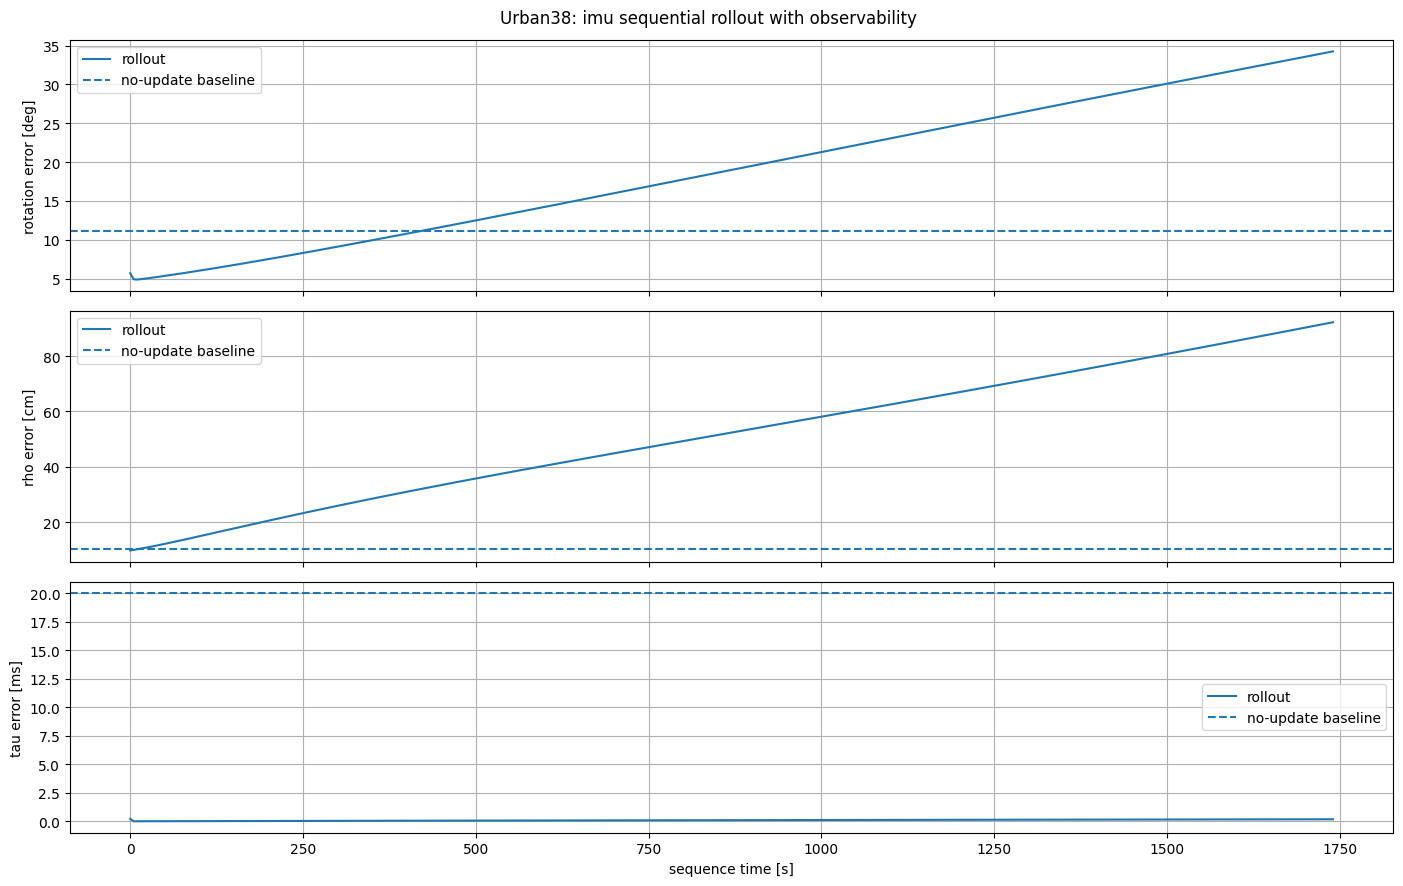

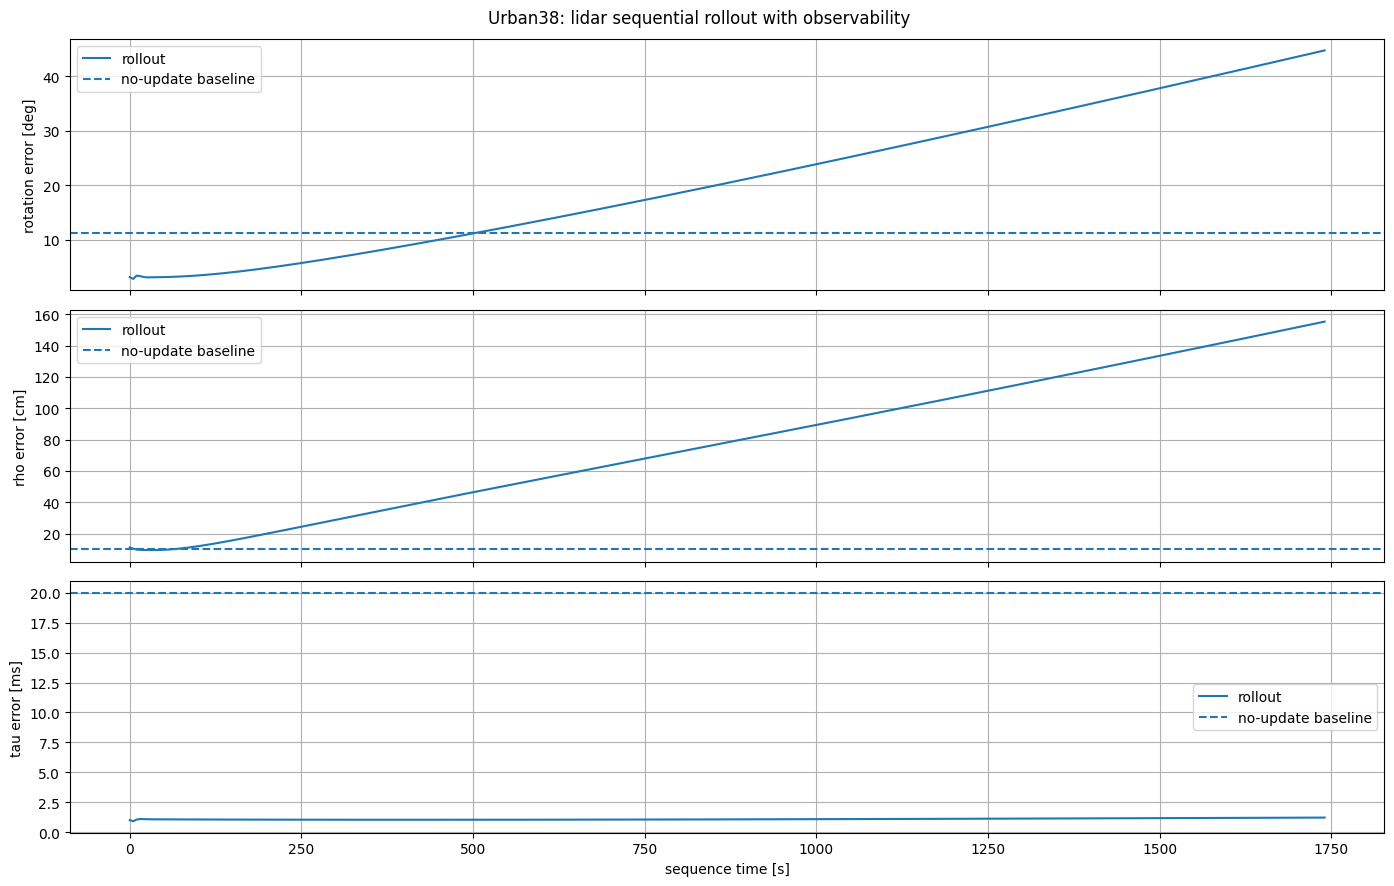

In [14]:
def plot_rollout_error_norms(history, calibration_key):
    result = history[calibration_key]
    error_xi = result["error_after_xi"]
    error_tau = result["error_after_tau"][:, 0]
    times_s = np.arange(len(error_xi)) * windowing_config.window_stride_s
    rotation_error_deg = np.rad2deg(np.linalg.norm(error_xi[:, :3], axis=1))
    translation_error_cm = 100.0 * np.linalg.norm(error_xi[:, 3:], axis=1)
    time_offset_error_ms = 1000.0 * np.abs(error_tau)
    initial_rotation_deg = np.rad2deg(np.linalg.norm(INITIAL_DELTA_XI[calibration_key][:3]))
    initial_translation_cm = 100.0 * np.linalg.norm(INITIAL_DELTA_XI[calibration_key][3:])
    initial_tau_ms = 1000.0 * abs(INITIAL_DELTA_TAU_S[calibration_key])

    fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
    axes[0].plot(times_s, rotation_error_deg, label="rollout")
    axes[0].axhline(initial_rotation_deg, linestyle="--", label="no-update baseline")
    axes[0].set_ylabel("rotation error [deg]")
    axes[0].grid(True)
    axes[0].legend()
    axes[1].plot(times_s, translation_error_cm, label="rollout")
    axes[1].axhline(initial_translation_cm, linestyle="--", label="no-update baseline")
    axes[1].set_ylabel("rho error [cm]")
    axes[1].grid(True)
    axes[1].legend()
    axes[2].plot(times_s, time_offset_error_ms, label="rollout")
    axes[2].axhline(initial_tau_ms, linestyle="--", label="no-update baseline")
    axes[2].set_ylabel("tau error [ms]")
    axes[2].set_xlabel("sequence time [s]")
    axes[2].grid(True)
    axes[2].legend()
    fig.suptitle(f"{SEQUENCE_NAME}: {calibration_key} sequential rollout with observability")
    fig.tight_layout()
    plt.show()

plot_rollout_error_norms(rollout_history, "imu")
plot_rollout_error_norms(rollout_history, "lidar")

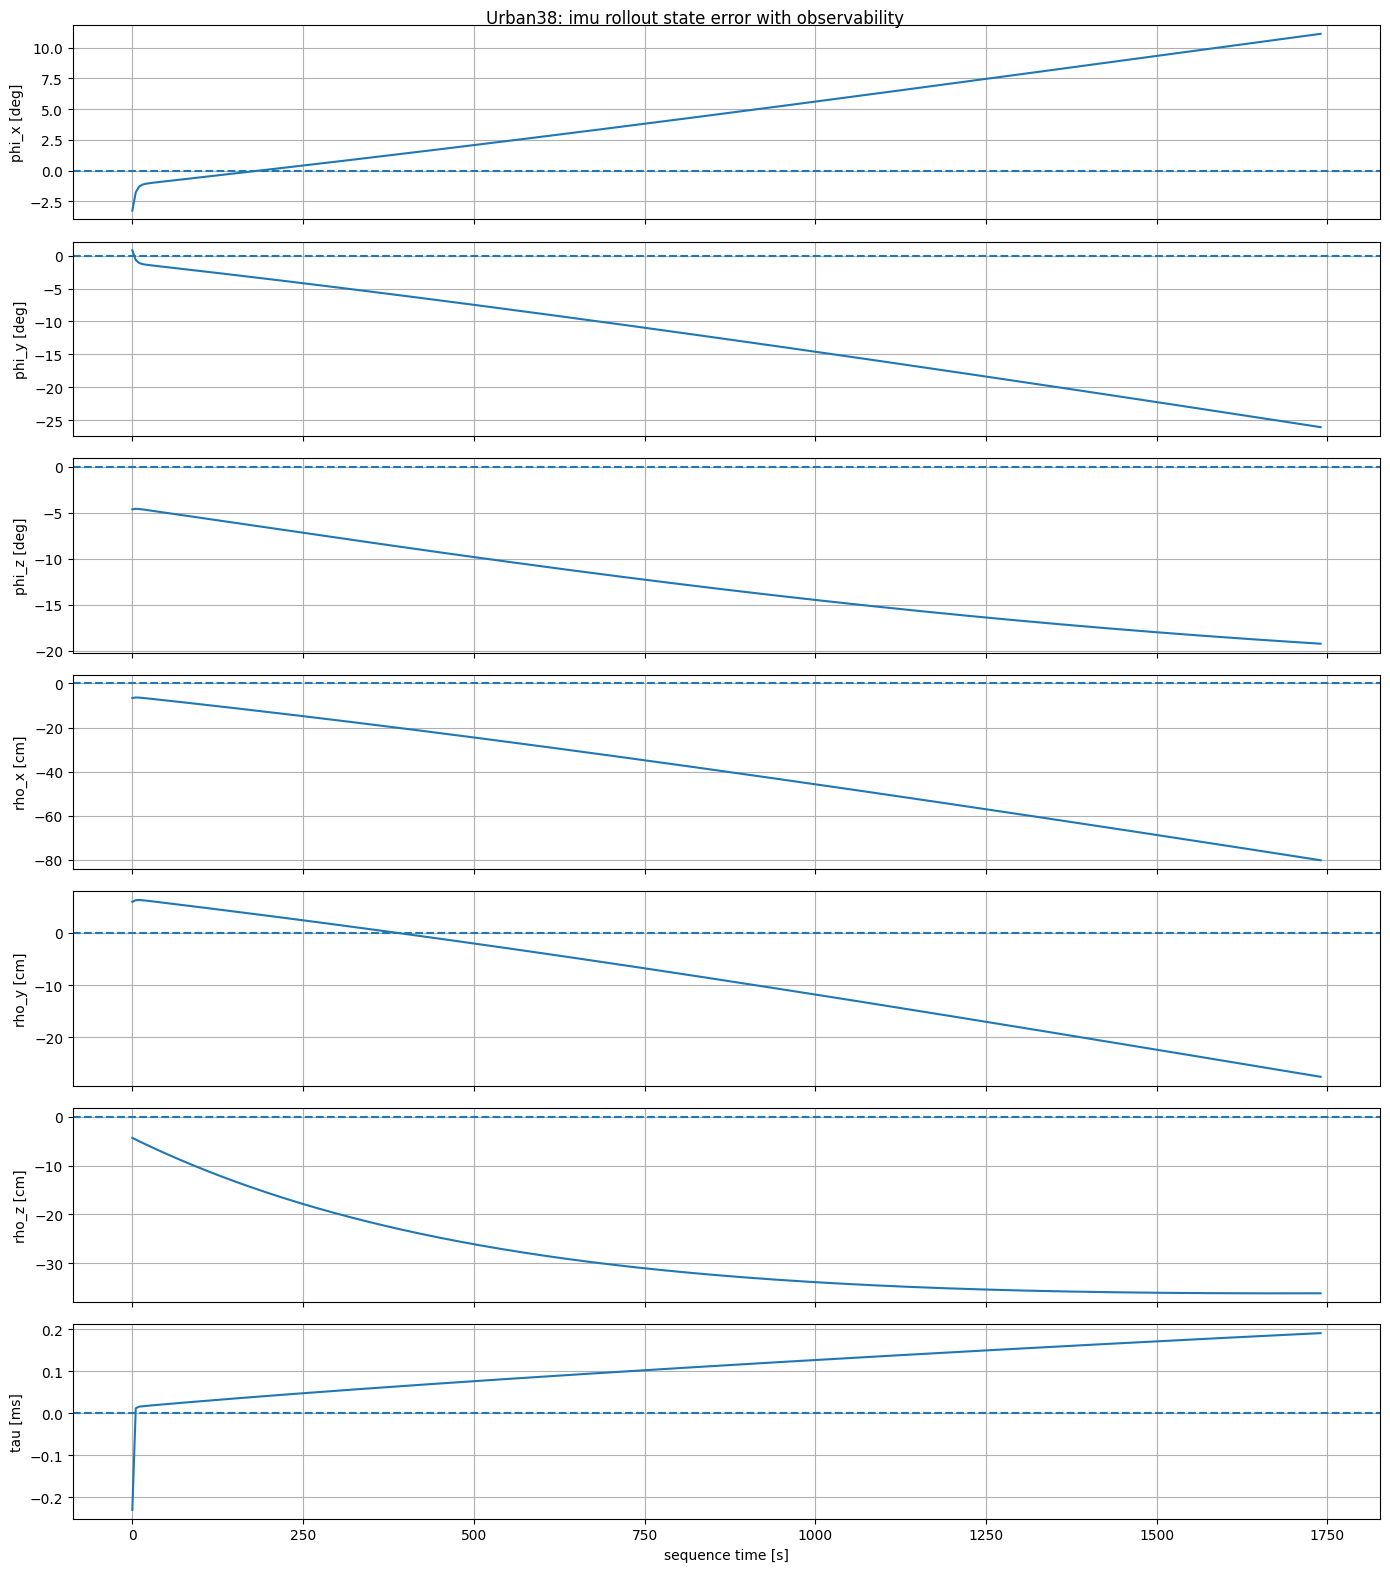

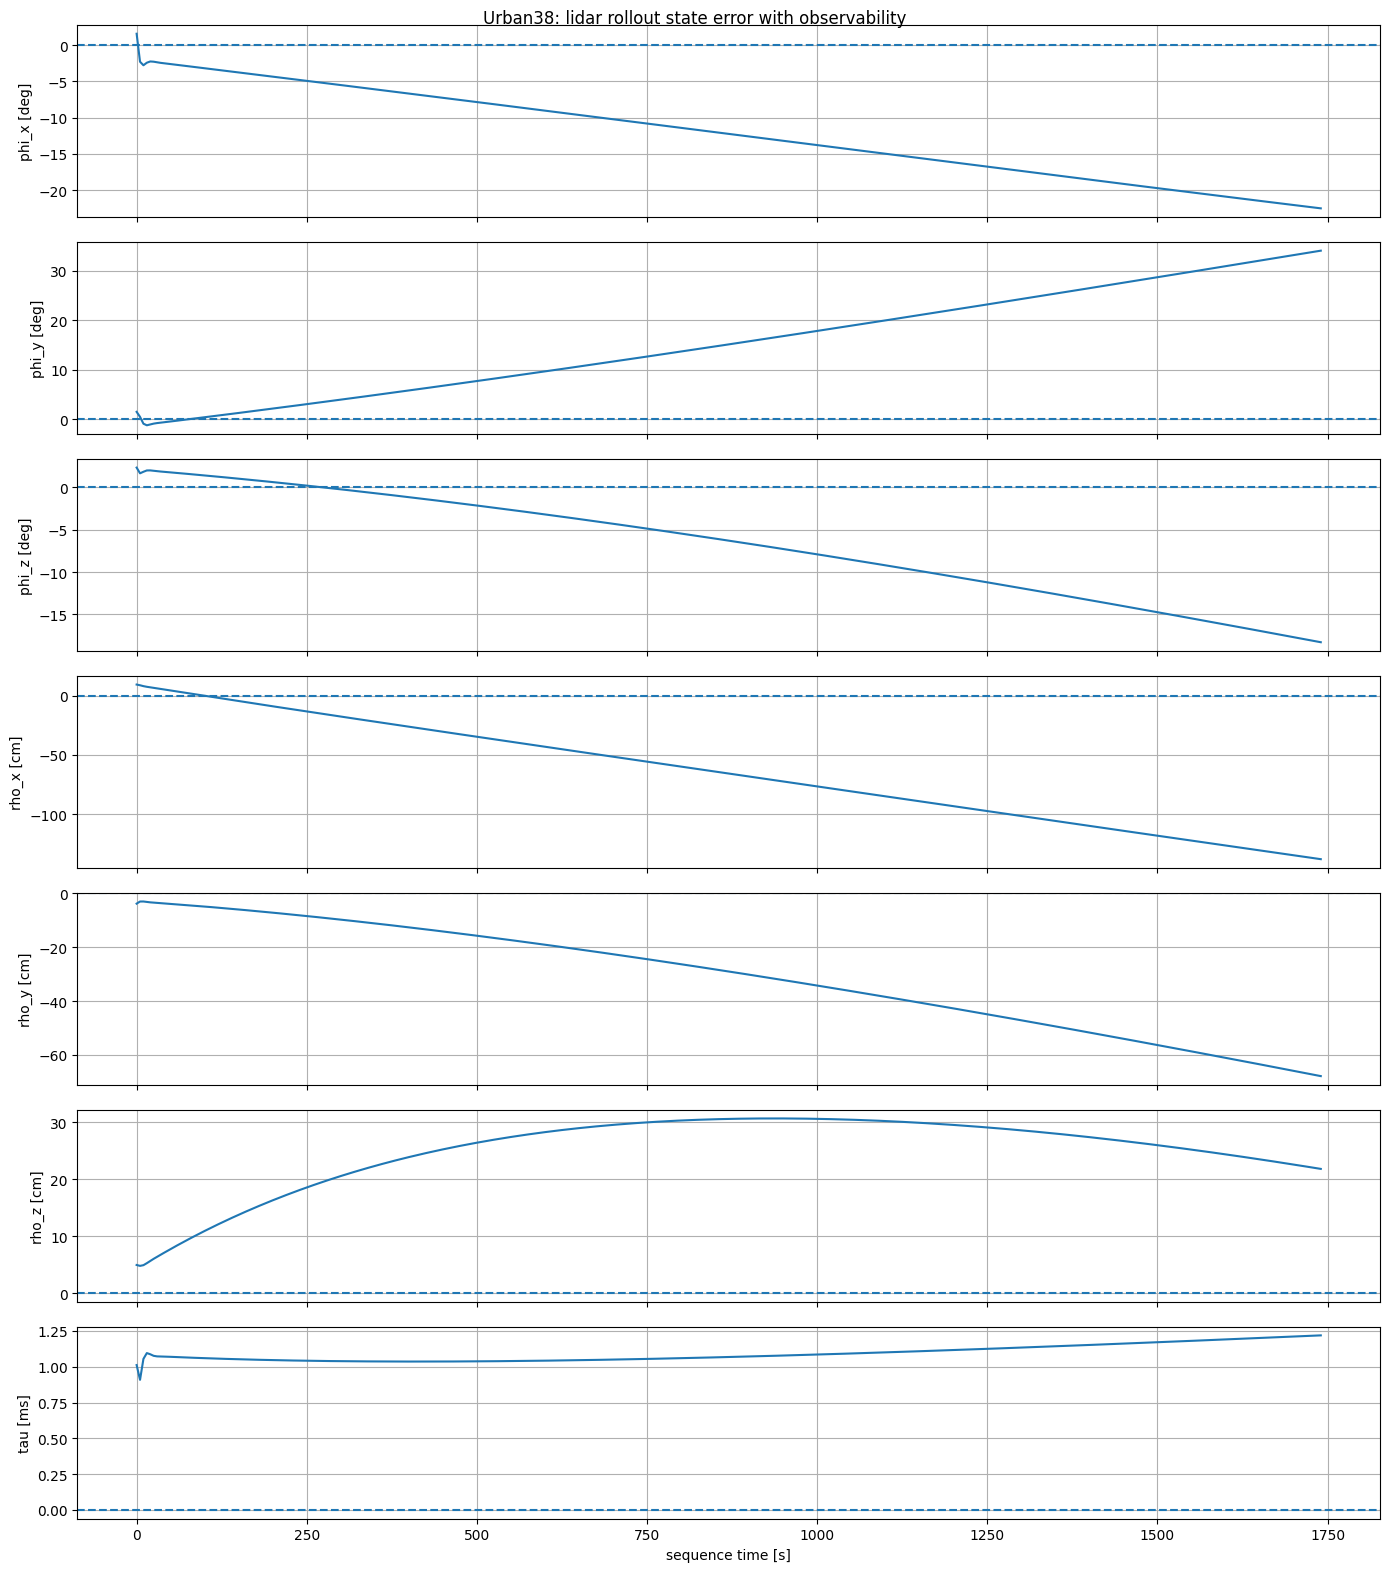

In [15]:
COMPONENT_NAMES = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z")

def plot_rollout_components(history, calibration_key):
    result = history[calibration_key]
    error_xi = result["error_after_xi"]
    error_tau = result["error_after_tau"][:, 0]
    times_s = np.arange(len(error_xi)) * windowing_config.window_stride_s
    fig, axes = plt.subplots(7, 1, figsize=(14, 16), sharex=True)

    for component_index in range(3):
        axes[component_index].plot(times_s, np.rad2deg(error_xi[:, component_index]))
        axes[component_index].axhline(0.0, linestyle="--")
        axes[component_index].set_ylabel(f"{COMPONENT_NAMES[component_index]} [deg]")
        axes[component_index].grid(True)

    for component_index in range(3, 6):
        axes[component_index].plot(times_s, 100.0 * error_xi[:, component_index])
        axes[component_index].axhline(0.0, linestyle="--")
        axes[component_index].set_ylabel(f"{COMPONENT_NAMES[component_index]} [cm]")
        axes[component_index].grid(True)

    axes[-1].plot(times_s, 1000.0 * error_tau)
    axes[-1].axhline(0.0, linestyle="--")
    axes[-1].set_ylabel("tau [ms]")
    axes[-1].set_xlabel("sequence time [s]")
    axes[-1].grid(True)
    fig.suptitle(f"{SEQUENCE_NAME}: {calibration_key} rollout state error with observability")
    fig.tight_layout()
    plt.show()

plot_rollout_components(rollout_history, "imu")
plot_rollout_components(rollout_history, "lidar")

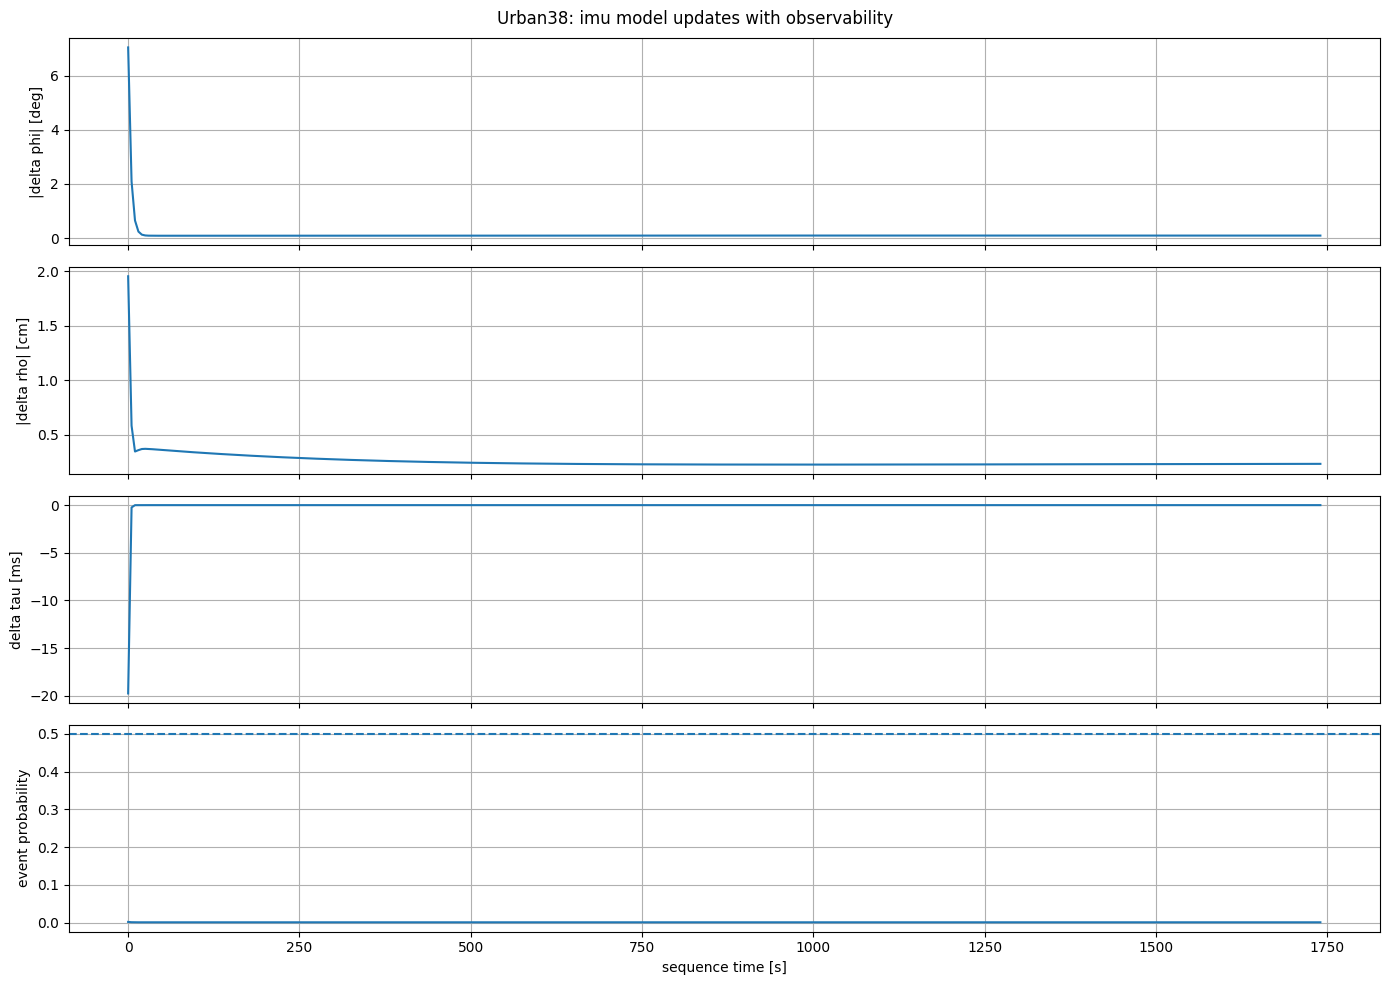

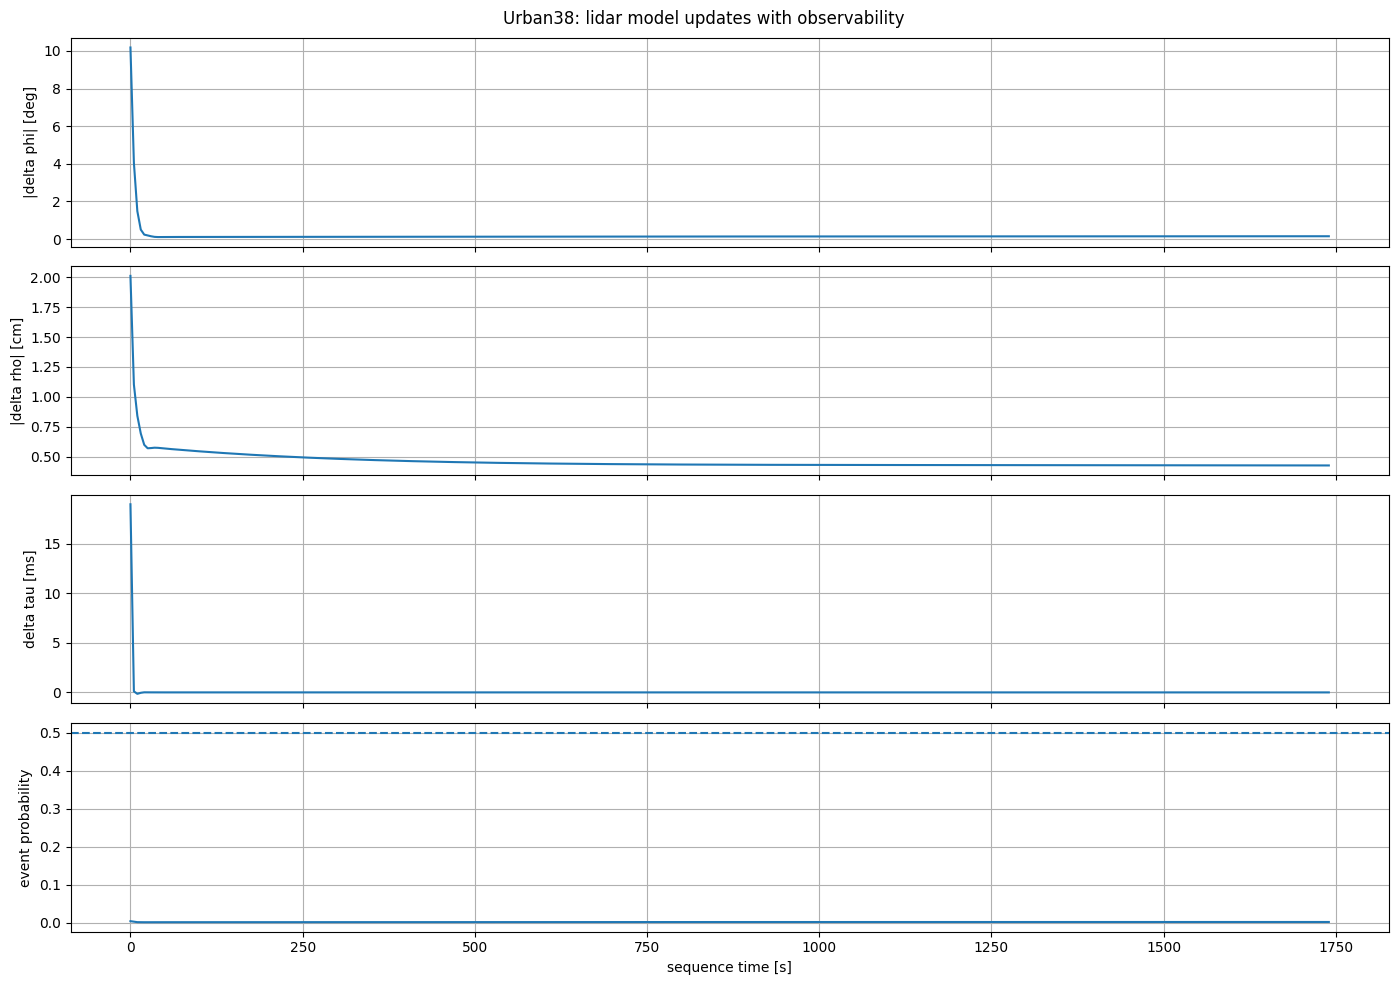

In [16]:
def plot_predicted_updates(history, calibration_key):
    result = history[calibration_key]
    delta_xi = result["predicted_delta_xi"]
    delta_tau = result["predicted_delta_tau"][:, 0]
    event_probability = result["event_probability"][:, 0]
    times_s = np.arange(len(delta_xi)) * windowing_config.window_stride_s
    rotation_update_deg = np.rad2deg(np.linalg.norm(delta_xi[:, :3], axis=1))
    translation_update_cm = 100.0 * np.linalg.norm(delta_xi[:, 3:], axis=1)

    fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
    axes[0].plot(times_s, rotation_update_deg)
    axes[0].set_ylabel("|delta phi| [deg]")
    axes[1].plot(times_s, translation_update_cm)
    axes[1].set_ylabel("|delta rho| [cm]")
    axes[2].plot(times_s, 1000.0 * delta_tau)
    axes[2].set_ylabel("delta tau [ms]")
    axes[3].plot(times_s, event_probability)
    axes[3].axhline(0.5, linestyle="--")
    axes[3].set_ylabel("event probability")
    axes[3].set_xlabel("sequence time [s]")

    for axis in axes:
        axis.grid(True)

    fig.suptitle(f"{SEQUENCE_NAME}: {calibration_key} model updates with observability")
    fig.tight_layout()
    plt.show()

plot_predicted_updates(rollout_history, "imu")
plot_predicted_updates(rollout_history, "lidar")

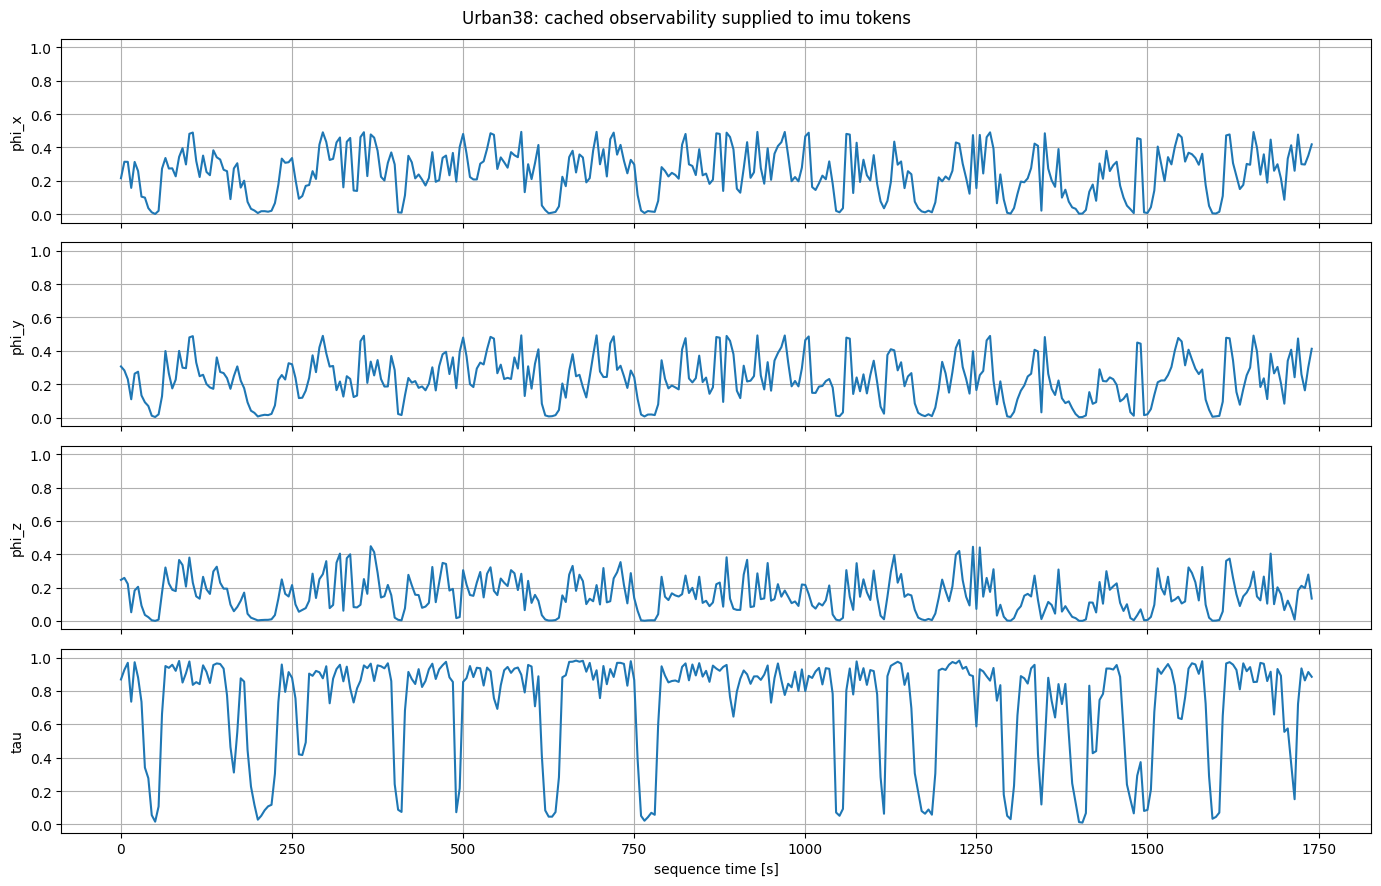


imu per-coordinate statistics:
phi_x   min=0.001326  mean=0.250107  max=0.493414
phi_y   min=0.002318  mean=0.231114  max=0.492762
phi_z   min=0.000710  mean=0.155775  max=0.448042
rho_x   min=0.000000  mean=0.000000  max=0.000000
rho_y   min=0.000000  mean=0.000000  max=0.000000
rho_z   min=0.000000  mean=0.000000  max=0.000000
tau     min=0.010543  mean=0.723641  max=0.981978


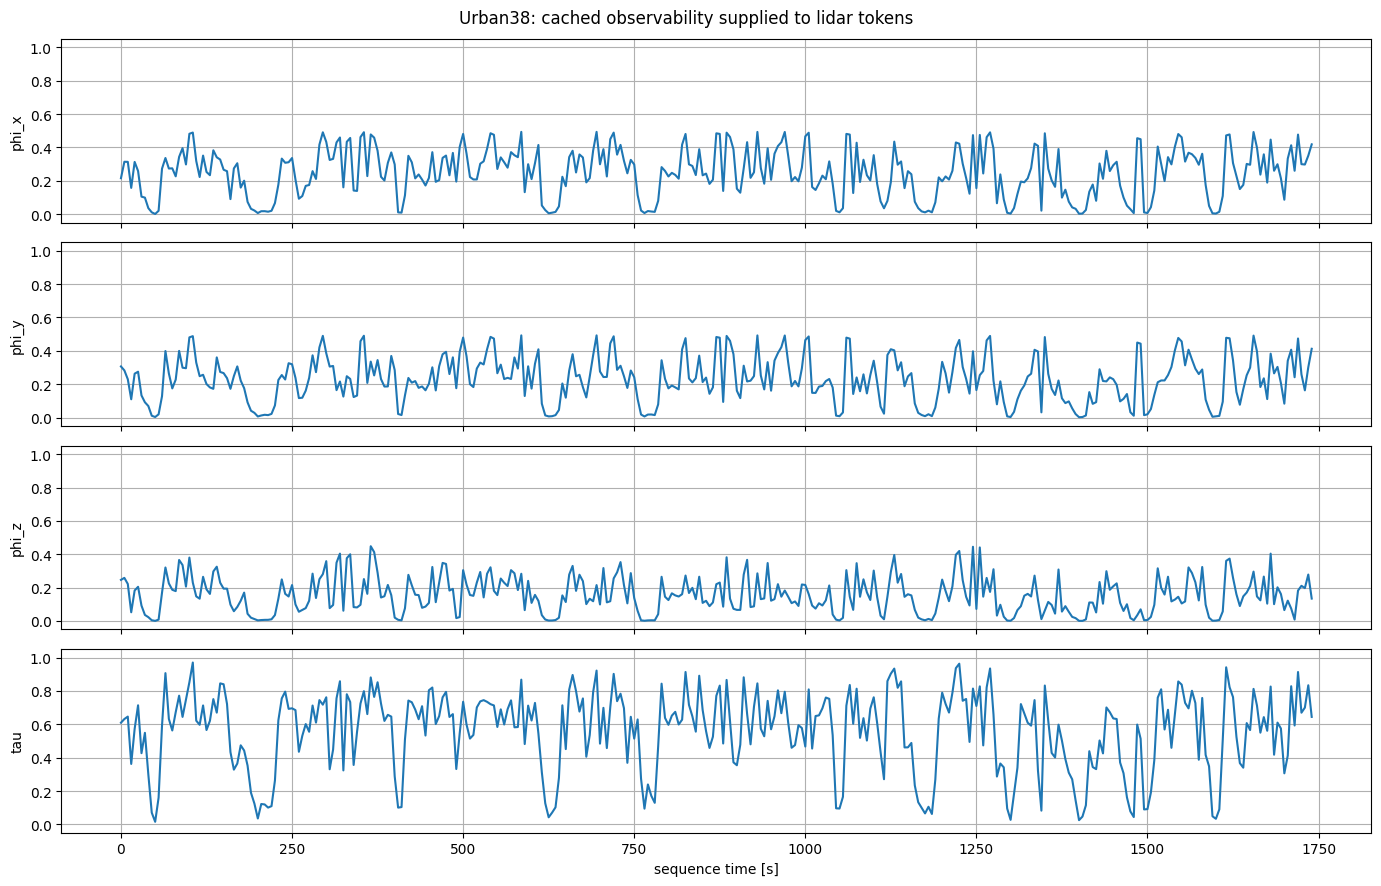


lidar per-coordinate statistics:
phi_x   min=0.001326  mean=0.250107  max=0.493416
phi_y   min=0.002318  mean=0.231115  max=0.492760
phi_z   min=0.000710  mean=0.155775  max=0.448042
rho_x   min=0.000000  mean=0.000000  max=0.000000
rho_y   min=0.000000  mean=0.000000  max=0.000000
rho_z   min=0.000000  mean=0.000000  max=0.000000
tau     min=0.015451  mean=0.558545  max=0.969999


In [17]:
##################################################
# Cached observability supplied to the network
##################################################

INFORMATIVE_OBSERVABILITY_COMPONENTS = (
    ("phi_x", 0),
    ("phi_y", 1),
    ("phi_z", 2),
    ("tau", 6),
)

times_s = (
    np.arange(
        len(
            rollout_indices
        )
    )
    * windowing_config.window_stride_s
)


def plot_cached_observability(
    observability_history,
    calibration_key,
):
    values = observability_history[
        calibration_key
    ]

    fig, axes = plt.subplots(
        len(
            INFORMATIVE_OBSERVABILITY_COMPONENTS
        ),
        1,
        figsize=(14, 9),
        sharex=True,
    )

    for axis, (
        component_name,
        component_index,
    ) in zip(
        axes,
        INFORMATIVE_OBSERVABILITY_COMPONENTS,
    ):
        axis.plot(
            times_s,
            values[
                :,
                component_index,
            ],
        )

        axis.set_ylabel(
            component_name
        )

        axis.set_ylim(
            -0.05,
            1.05,
        )

        axis.grid(
            True
        )

    axes[-1].set_xlabel(
        "sequence time [s]"
    )

    fig.suptitle(
        f"{SEQUENCE_NAME}: cached observability supplied to {calibration_key} tokens"
    )

    fig.tight_layout()

    plt.show()

    print()
    print(
        calibration_key,
        "per-coordinate statistics:",
    )

    for component_index, component_name in enumerate(
        OBSERVABILITY_COORDINATE_ORDER
    ):
        component_values = values[
            :,
            component_index,
        ]

        print(
            f"{component_name:6s}  "
            f"min={component_values.min():.6f}  "
            f"mean={component_values.mean():.6f}  "
            f"max={component_values.max():.6f}"
        )


plot_cached_observability(
    observability_history,
    "imu",
)

plot_cached_observability(
    observability_history,
    "lidar",
)

In [18]:
BIAS_NUM_WINDOWS = min(100, len(rollout_indices))
bias_indices = np.unique(np.linspace(rollout_indices[0], rollout_indices[-1], BIAS_NUM_WINDOWS).round().astype(int))

def collect_zero_error_updates(apply_noise):
    generator = torch.Generator(device=DEVICE.type).manual_seed(ROLLOUT_AUGMENTATION_SEED)
    collected = {calibration_key: {"xi": [], "tau": []} for calibration_key in CALIBRATION_KEYS}

    model.eval()

    with torch.no_grad():
        for dataset_index in bias_indices:
            window = window_batch_to(collate_windows([rollout_dataset[dataset_index]]), DEVICE, dtype=MODEL_DTYPE)
            true_calibration = window.current_calibration

            if apply_noise:
                window = rollout_augmentation_pipeline(window, generator=generator).augmented_window

            observability = cached_observability_for_rollout_index(dataset_index, device=DEVICE, dtype=MODEL_DTYPE)
            result = forward_cached_rollout_step(window, true_calibration, observability)

            for calibration_key, prediction in result.model_output.predictions.items():
                collected[calibration_key]["xi"].append(prediction.delta_xi[0].cpu())
                collected[calibration_key]["tau"].append(prediction.delta_tau[0].cpu())

    for calibration_key in collected:
        collected[calibration_key]["xi"] = torch.stack(collected[calibration_key]["xi"]).numpy()
        collected[calibration_key]["tau"] = torch.stack(collected[calibration_key]["tau"]).numpy()[:, 0]

    return collected


def print_zero_error_bias(collected, title):
    names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z")

    print("=" * 90)
    print(title)
    print("=" * 90)

    for calibration_key in CALIBRATION_KEYS:
        xi = collected[calibration_key]["xi"]
        tau = collected[calibration_key]["tau"]

        print()
        print(calibration_key)

        for component_index, name in enumerate(names):
            values = xi[:, component_index]

            if component_index < 3:
                values = np.rad2deg(values)
                unit = "deg"
            else:
                values = 100.0 * values
                unit = "cm"

            print(f"{name:5s}  mean={values.mean():+9.5f} {unit}  mean_abs={np.mean(np.abs(values)):9.5f} {unit}  rmse={np.sqrt(np.mean(values**2)):9.5f} {unit}")

        tau_ms = 1000.0 * tau
        print(f"{'tau':5s}  mean={tau_ms.mean():+9.5f} ms   mean_abs={np.mean(np.abs(tau_ms)):9.5f} ms   rmse={np.sqrt(np.mean(tau_ms**2)):9.5f} ms")


zero_error_clean = collect_zero_error_updates(apply_noise=False)
print_zero_error_bias(zero_error_clean, "ZERO-ERROR FIXED-POINT TEST: CLEAN")

if USE_MEASUREMENT_NOISE:
    zero_error_noisy = collect_zero_error_updates(apply_noise=True)
    print()
    print_zero_error_bias(zero_error_noisy, "ZERO-ERROR FIXED-POINT TEST: MEASUREMENT NOISE")

ZERO-ERROR FIXED-POINT TEST: CLEAN

imu
phi_x  mean= -0.51443 deg  mean_abs=  0.51443 deg  rmse=  0.51443 deg
phi_y  mean= -0.53903 deg  mean_abs=  0.53903 deg  rmse=  0.53903 deg
phi_z  mean= +0.05383 deg  mean_abs=  0.05383 deg  rmse=  0.05383 deg
rho_x  mean= +0.32589 cm  mean_abs=  0.32589 cm  rmse=  0.32589 cm
rho_y  mean= -0.09660 cm  mean_abs=  0.09660 cm  rmse=  0.09660 cm
rho_z  mean= +0.39418 cm  mean_abs=  0.39418 cm  rmse=  0.39418 cm
tau    mean= +0.03107 ms   mean_abs=  0.03107 ms   rmse=  0.03107 ms

lidar
phi_x  mean= +0.00876 deg  mean_abs=  0.00876 deg  rmse=  0.00876 deg
phi_y  mean= -1.00910 deg  mean_abs=  1.00910 deg  rmse=  1.00910 deg
phi_z  mean= +0.21271 deg  mean_abs=  0.21271 deg  rmse=  0.21271 deg
rho_x  mean= +0.23201 cm  mean_abs=  0.23201 cm  rmse=  0.23201 cm
rho_y  mean= +0.10420 cm  mean_abs=  0.10420 cm  rmse=  0.10420 cm
rho_z  mean= -0.45648 cm  mean_abs=  0.45648 cm  rmse=  0.45648 cm
tau    mean= -1.09886 ms   mean_abs=  1.09886 ms   rmse=  1.09

In [19]:
##################################################
# Measurement-noise wiring and model-response diagnostic
##################################################

NOISE_DIAGNOSTIC_DATASET_INDEX = rollout_indices[len(rollout_indices) // 2]
NOISE_DIAGNOSTIC_SEED = 91753

noise_diagnostic_config = AugmentationConfig(
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(
        enabled=True,
        vector_by_type={
            MeasurementType.IMU_GYROSCOPE: VectorNoiseConfig(gaussian_std=0.01, window_bias_std=0.003),
            MeasurementType.IMU_ACCELEROMETER: VectorNoiseConfig(gaussian_std=0.08, window_bias_std=0.03),
        },
        se3_by_type={
            MeasurementType.LIDAR_POSE: SE3NoiseConfig(rotation_std=np.deg2rad(0.15), translation_std=0.01),
        },
    ),
)

noise_diagnostic_pipeline = AugmentationPipeline(noise_diagnostic_config)

clean_window = window_batch_to(collate_windows([rollout_dataset[NOISE_DIAGNOSTIC_DATASET_INDEX]]), DEVICE, dtype=MODEL_DTYPE)
noise_generator = torch.Generator(device=DEVICE.type).manual_seed(NOISE_DIAGNOSTIC_SEED)
noisy_window = noise_diagnostic_pipeline(clean_window, generator=noise_generator).augmented_window

print("=" * 100)
print("MEASUREMENT CHANGES")
print("=" * 100)

for stream_key in clean_window.streams:
    clean_stream = clean_window.streams[stream_key]
    noisy_stream = noisy_window.streams[stream_key]

    clean_values = clean_stream.values
    noisy_values = noisy_stream.values

    mask = clean_stream.sample_mask
    if mask is None:
        mask = torch.ones(clean_values.shape[:2], dtype=torch.bool, device=clean_values.device)

    clean_valid = clean_values[mask]
    noisy_valid = noisy_values[mask]

    print()
    print(stream_key)
    print("shape:", tuple(clean_valid.shape))
    print("tensor mean abs change:", float(torch.mean(torch.abs(noisy_valid - clean_valid))))
    print("tensor max abs change:", float(torch.max(torch.abs(noisy_valid - clean_valid))))

    if clean_valid.ndim == 3 and clean_valid.shape[-2:] == (4, 4):
        relative_change = noisy_valid @ torch.linalg.inv(clean_valid)
        change_xi = se3_log(relative_change)
        rotation_change_deg = torch.rad2deg(torch.linalg.vector_norm(change_xi[:, :3], dim=-1))
        translation_change_cm = 100.0 * torch.linalg.vector_norm(change_xi[:, 3:], dim=-1)

        print("SE3 rotation change: mean =", float(rotation_change_deg.mean()), "deg, max =", float(rotation_change_deg.max()), "deg")
        print("SE3 translation change: mean =", float(translation_change_cm.mean()), "cm, max =", float(translation_change_cm.max()), "cm")

    else:
        flattened_difference = (noisy_valid - clean_valid).reshape(noisy_valid.shape[0], -1)
        sample_difference_norm = torch.linalg.vector_norm(flattened_difference, dim=-1)

        print("sample L2 change: mean =", float(sample_difference_norm.mean()), "max =", float(sample_difference_norm.max()))

print()
print("=" * 100)
print("CALIBRATION STATE CHANGES CAUSED BY NOISE AUGMENTATION")
print("=" * 100)

for calibration_key in CALIBRATION_KEYS:
    clean_state = clean_window.current_calibration[calibration_key]
    noisy_state = noisy_window.current_calibration[calibration_key]

    transform_difference = torch.max(torch.abs(noisy_state.transform - clean_state.transform))
    tau_difference = torch.max(torch.abs(noisy_state.time_offset - clean_state.time_offset))

    print(calibration_key, "max transform change =", float(transform_difference), "max tau change =", float(tau_difference))

print()
print("=" * 100)
print("MODEL RESPONSE AT THE TRUE CALIBRATION")
print("=" * 100)

true_calibration = clean_window.current_calibration
observability = cached_observability_for_rollout_index(NOISE_DIAGNOSTIC_DATASET_INDEX, device=DEVICE, dtype=MODEL_DTYPE)

model.eval()

with torch.no_grad():
    clean_result = forward_cached_rollout_step(clean_window, true_calibration, observability)
    noisy_result = forward_cached_rollout_step(noisy_window, true_calibration, observability)

for calibration_key in CALIBRATION_KEYS:
    clean_prediction = clean_result.model_output.predictions[calibration_key]
    noisy_prediction = noisy_result.model_output.predictions[calibration_key]

    clean_xi = clean_prediction.delta_xi[0].detach().cpu().numpy()
    noisy_xi = noisy_prediction.delta_xi[0].detach().cpu().numpy()

    clean_tau_ms = 1000.0 * float(clean_prediction.delta_tau[0, 0].detach().cpu())
    noisy_tau_ms = 1000.0 * float(noisy_prediction.delta_tau[0, 0].detach().cpu())

    print()
    print(calibration_key)

    for component_index, component_name in enumerate(("phi_x", "phi_y", "phi_z")):
        print(component_name, "clean =", np.rad2deg(clean_xi[component_index]), "deg, noisy =", np.rad2deg(noisy_xi[component_index]), "deg, difference =", np.rad2deg(noisy_xi[component_index] - clean_xi[component_index]), "deg")

    for component_index, component_name in zip((3, 4, 5), ("rho_x", "rho_y", "rho_z")):
        print(component_name, "clean =", 100.0 * clean_xi[component_index], "cm, noisy =", 100.0 * noisy_xi[component_index], "cm, difference =", 100.0 * (noisy_xi[component_index] - clean_xi[component_index]), "cm")

    print("tau clean =", clean_tau_ms, "ms, noisy =", noisy_tau_ms, "ms, difference =", noisy_tau_ms - clean_tau_ms, "ms")

MEASUREMENT CHANGES

gyro
shape: (500, 3)
tensor mean abs change: 0.00868111103773117
tensor max abs change: 0.037958525121212006
sample L2 change: mean = 0.01720346324145794 max = 0.04578862711787224

accel
shape: (500, 3)
tensor mean abs change: 0.06775228679180145
tensor max abs change: 0.2580604553222656
sample L2 change: mean = 0.1355239897966385 max = 0.3082627058029175

lidar
shape: (48, 4, 4)
tensor mean abs change: 0.002373921452090144
tensor max abs change: 0.02987530827522278
SE3 rotation change: mean = 0.2635684013366699 deg, max = 0.4884895980358124 deg
SE3 translation change: mean = 1.5449063777923584 cm, max = 3.5666089057922363 cm

CALIBRATION STATE CHANGES CAUSED BY NOISE AUGMENTATION
imu max transform change = 0.0 max tau change = 0.0
lidar max transform change = 0.0 max tau change = 0.0

MODEL RESPONSE AT THE TRUE CALIBRATION

imu
phi_x clean = -0.514426 deg, noisy = -0.514426 deg, difference = 0.0 deg
phi_y clean = -0.5390306 deg, noisy = -0.5390306 deg, difference 

OBSERVABILITY SHUFFLE SENSITIVITY
Only observability changes between the paired forward passes.
Measurements and current calibration are identical.

imu
component      obs |Δ|       pred |Δ|    pred RMSE Δ       pred std      Δ/std      corr
phi_x         0.19059    0.00000 deg    0.00000 deg    0.00000 deg      0.000       nan
phi_y         0.16766    0.00000 deg    0.00000 deg    0.00000 deg      0.000       nan
phi_z         0.14382    0.00000 deg    0.00000 deg    0.00000 deg      0.000       nan
rho_x         0.00000    0.00000 cm     0.00000 cm     0.00000 cm       0.000       nan
rho_y         0.00000    0.00000 cm     0.00000 cm     0.00000 cm       0.000       nan
rho_z         0.00000    0.00000 cm     0.00000 cm     0.00000 cm       0.000       nan
tau           0.34565    0.00000 ms     0.00000 ms     0.00000 ms         nan       nan

lidar
component      obs |Δ|       pred |Δ|    pred RMSE Δ       pred std      Δ/std      corr
phi_x         0.19059    0.00000 deg    0.0000

/home/camel/anaconda3/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


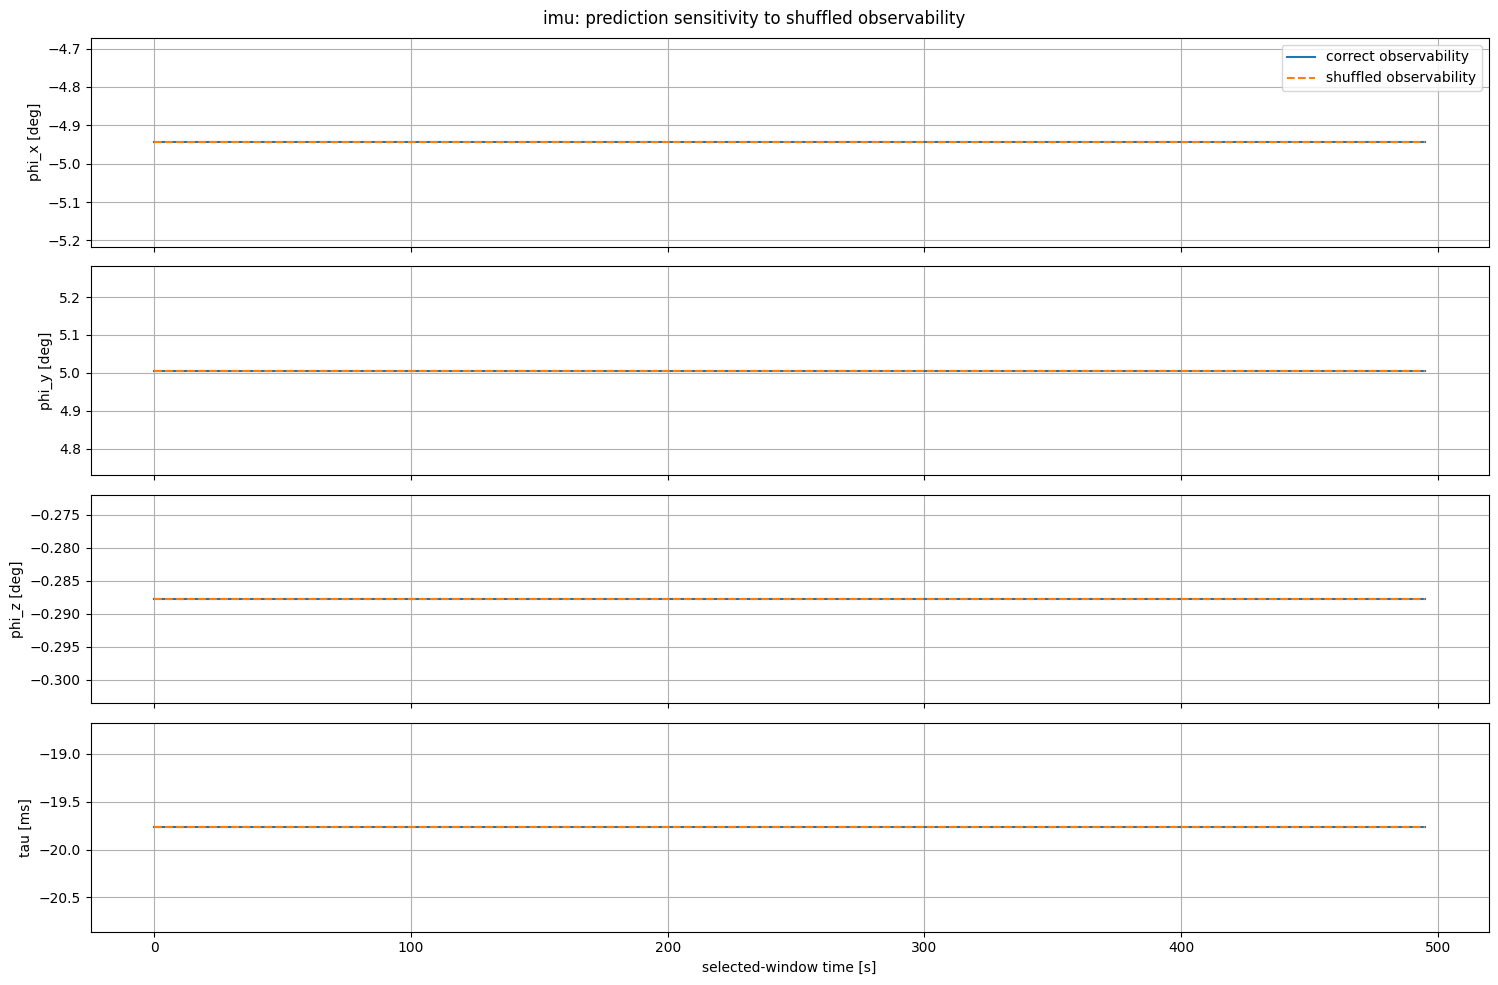

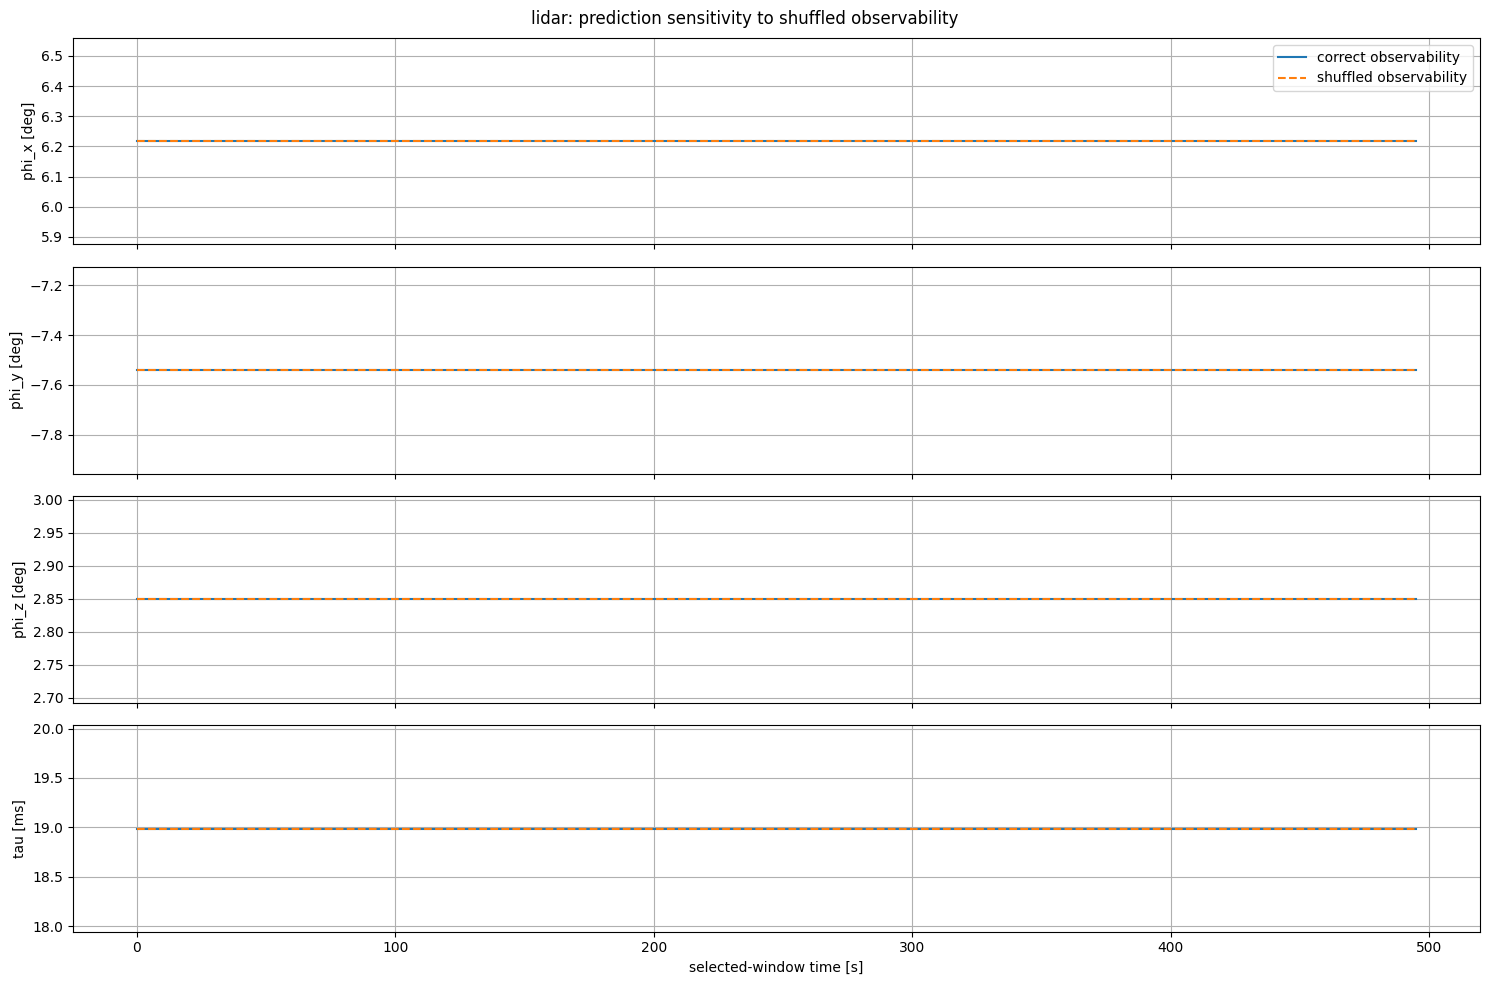

In [20]:
##################################################
# Observability-input sensitivity: correct vs shuffled
##################################################

OBSERVABILITY_SENSITIVITY_NUM_WINDOWS = min(100, len(rollout_indices))
OBSERVABILITY_SHUFFLE_SEED = 91827

selected_positions = np.linspace(0, len(rollout_indices) - 1, OBSERVABILITY_SENSITIVITY_NUM_WINDOWS).round().astype(int)
sensitivity_indices = np.asarray(rollout_indices)[selected_positions]

rng = np.random.default_rng(OBSERVABILITY_SHUFFLE_SEED)

if len(sensitivity_indices) > 1:
    permutation = rng.permutation(len(sensitivity_indices))

    while np.any(permutation == np.arange(len(sensitivity_indices))):
        permutation = rng.permutation(len(sensitivity_indices))

    shuffled_observability_indices = sensitivity_indices[permutation]
else:
    shuffled_observability_indices = sensitivity_indices.copy()

sensitivity_results = {
    calibration_key: {
        "true_observability": [],
        "shuffled_observability": [],
        "true_delta_xi": [],
        "shuffled_delta_xi": [],
        "true_delta_tau": [],
        "shuffled_delta_tau": [],
    }
    for calibration_key in CALIBRATION_KEYS
}

sensitivity_augmentation_generator = torch.Generator(device=DEVICE.type).manual_seed(ROLLOUT_AUGMENTATION_SEED)

model.eval()

with torch.no_grad():
    for dataset_index, shuffled_dataset_index in zip(sensitivity_indices, shuffled_observability_indices):
        window = window_batch_to(collate_windows([rollout_dataset[int(dataset_index)]]), DEVICE, dtype=MODEL_DTYPE)

        # Generate the measurement realization only once. Both forward passes therefore
        # see exactly the same measurements and exactly the same calibration state.
        window = rollout_augmentation_pipeline(window, generator=sensitivity_augmentation_generator).augmented_window

        true_observability = cached_observability_for_rollout_index(int(dataset_index), device=DEVICE, dtype=MODEL_DTYPE)
        shuffled_observability = cached_observability_for_rollout_index(int(shuffled_dataset_index), device=DEVICE, dtype=MODEL_DTYPE)

        true_result = forward_cached_rollout_step(window, initial_calibration, true_observability)
        shuffled_result = forward_cached_rollout_step(window, initial_calibration, shuffled_observability)

        for calibration_key in CALIBRATION_KEYS:
            true_prediction = true_result.model_output.predictions[calibration_key]
            shuffled_prediction = shuffled_result.model_output.predictions[calibration_key]

            sensitivity_results[calibration_key]["true_observability"].append(true_observability.calibration_features[calibration_key][0].detach().cpu())
            sensitivity_results[calibration_key]["shuffled_observability"].append(shuffled_observability.calibration_features[calibration_key][0].detach().cpu())
            sensitivity_results[calibration_key]["true_delta_xi"].append(true_prediction.delta_xi[0].detach().cpu())
            sensitivity_results[calibration_key]["shuffled_delta_xi"].append(shuffled_prediction.delta_xi[0].detach().cpu())
            sensitivity_results[calibration_key]["true_delta_tau"].append(true_prediction.delta_tau[0, 0].detach().cpu())
            sensitivity_results[calibration_key]["shuffled_delta_tau"].append(shuffled_prediction.delta_tau[0, 0].detach().cpu())

for calibration_key in CALIBRATION_KEYS:
    for field_name in sensitivity_results[calibration_key]:
        sensitivity_results[calibration_key][field_name] = torch.stack(sensitivity_results[calibration_key][field_name]).numpy()


##################################################
# Numerical summary
##################################################

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")

print("=" * 120)
print("OBSERVABILITY SHUFFLE SENSITIVITY")
print("=" * 120)
print("Only observability changes between the paired forward passes.")
print("Measurements and current calibration are identical.")
print()

for calibration_key in CALIBRATION_KEYS:
    result = sensitivity_results[calibration_key]

    true_observability = result["true_observability"]
    shuffled_observability = result["shuffled_observability"]

    true_prediction = np.concatenate([result["true_delta_xi"], result["true_delta_tau"][:, None]], axis=1)
    shuffled_prediction = np.concatenate([result["shuffled_delta_xi"], result["shuffled_delta_tau"][:, None]], axis=1)

    print(calibration_key)
    print(f"{'component':8s} {'obs |Δ|':>12s} {'pred |Δ|':>14s} {'pred RMSE Δ':>14s} {'pred std':>14s} {'Δ/std':>10s} {'corr':>9s}")

    for component_index, component_name in enumerate(component_names):
        observability_difference = np.mean(np.abs(shuffled_observability[:, component_index] - true_observability[:, component_index]))

        true_values = true_prediction[:, component_index]
        shuffled_values = shuffled_prediction[:, component_index]
        prediction_difference = shuffled_values - true_values

        if component_index < 3:
            scale, unit = 180.0 / np.pi, "deg"
        elif component_index < 6:
            scale, unit = 100.0, "cm"
        else:
            scale, unit = 1000.0, "ms"

        mean_abs_difference = scale * np.mean(np.abs(prediction_difference))
        rmse_difference = scale * np.sqrt(np.mean(prediction_difference ** 2))
        prediction_std = scale * np.std(true_values)
        normalized_difference = rmse_difference / prediction_std if prediction_std > 1e-12 else np.nan
        correlation = np.corrcoef(true_values, shuffled_values)[0, 1] if np.std(true_values) > 1e-12 and np.std(shuffled_values) > 1e-12 else np.nan

        print(f"{component_name:8s} {observability_difference:12.5f} {mean_abs_difference:10.5f} {unit:3s} {rmse_difference:10.5f} {unit:3s} {prediction_std:10.5f} {unit:3s} {normalized_difference:10.3f} {correlation:9.4f}")

    print()


##################################################
# Visual comparison
##################################################

times_s = np.arange(len(sensitivity_indices)) * windowing_config.window_stride_s
plot_components = (("phi_x", 0), ("phi_y", 1), ("phi_z", 2), ("tau", 6))

for calibration_key in CALIBRATION_KEYS:
    result = sensitivity_results[calibration_key]

    true_prediction = np.concatenate([result["true_delta_xi"], result["true_delta_tau"][:, None]], axis=1)
    shuffled_prediction = np.concatenate([result["shuffled_delta_xi"], result["shuffled_delta_tau"][:, None]], axis=1)

    fig, axes = plt.subplots(len(plot_components), 1, figsize=(15, 10), sharex=True)

    for axis, (component_name, component_index) in zip(axes, plot_components):
        if component_index < 3:
            true_values = np.rad2deg(true_prediction[:, component_index])
            shuffled_values = np.rad2deg(shuffled_prediction[:, component_index])
            unit = "deg"
        else:
            true_values = 1000.0 * true_prediction[:, component_index]
            shuffled_values = 1000.0 * shuffled_prediction[:, component_index]
            unit = "ms"

        axis.plot(times_s, true_values, label="correct observability")
        axis.plot(times_s, shuffled_values, linestyle="--", label="shuffled observability")
        axis.set_ylabel(f"{component_name} [{unit}]")
        axis.grid(True)

    axes[0].legend()
    axes[-1].set_xlabel("selected-window time [s]")
    fig.suptitle(f"{calibration_key}: prediction sensitivity to shuffled observability")
    fig.tight_layout()
    plt.show()